# **Домашнее задание №1 (pro)**

В этом домашнем задании вам будет необходимо:
*  обучить модель регрессии для предсказания стоимости автомобилей;


**Оценивание**

Максимальная оценка за ДЗ — **10 баллов**:
- Части 1–5 (EDA, модели, категориальные признаки, Feature Engineering, бизнес-метрика) — 5 баллов;
- Часть 6, оформление репозитория — 2 балла;
- Часть 7, Streamlit-приложение — 3 балла.

**Дедлайн: 2 декабря**

**Примечание**

В каждой части оцениваются как код, **так и ответы на вопросы.**

Если нет одного и/или другого, то часть баллов за соответствующее задание снимается.

In [1]:
!pip install -q ydata-profiling "numpy<2.4"  # numba в Colab пока не поддерживает NumPy 2.4

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random
import seaborn as sns
from ydata_profiling import ProfileReport

from sklearn.linear_model import LinearRegression, Lasso, ElasticNet, Ridge
from sklearn.metrics import r2_score, mean_squared_error as MSE
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder  # для OHE можно использовать и pd.get_dummies

random.seed(42)
np.random.seed(42)

/tmp/ipykernel_11000/2223499982.py:6: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport


### **Задание 0**
Давайте зафиксируем важный момент.

**Задание 0 (0 баллов).**
Изучите и ответьте на вопрос: для чего фиксируем сиды в домашках?

`Для воспроизводимости экспериментов`

# **Часть 1 | EDA**


Первая часть состоит из классических шагов EDA:

- Базовый EDA и обработка признаков (1.4 балла)
- Визуализации признаков и их анализ (0.9 балла)

Всего за эту часть можно набрать 2.3 балла.

## **Простейший EDA и обработка признаков (1.4 балла)**

In [2]:
df_train = pd.read_csv('https://raw.githubusercontent.com/Murcha1990/MLDS_ML_2022/main/Hometasks/HT1/cars_train.csv')
df_test = pd.read_csv('https://raw.githubusercontent.com/Murcha1990/MLDS_ML_2022/main/Hometasks/HT1/cars_test.csv')

print("Train data shape:", df_train.shape)
print("Test data shape: ", df_test.shape)

Train data shape: (6999, 13)
Test data shape:  (1000, 13)


### **Задание 1 (0.4 балла)**
Выполните операции, направленные на базовое исследование данных:

- [ ] Посмотрите, есть ли в датасете пропуски. Запишите/выведите названия колонок, для которых есть пропущенные значения (0.1 балла)
- [ ] Посмотрите, есть ли в данных явные дубликаты (0.05 балла)
- [ ] Постройте дашборд в одну строку, используя [ydata-profiling](https://github.com/ydataai/ydata-profiling) (0.1 балла)
- [ ] Опишите базовые выводы (какие — выберите сами), используя дашборд (0.15 балла).

In [3]:
for name, df in [("Train", df_train), ("Test", df_test)]:
  print(f"\n{name}:")
  missing = df.isna().sum()
  print("Пропуски:")
  print(missing[missing > 0])
  print("Дубликаты:", df.duplicated().sum())


Train:
Пропуски:
mileage      202
engine       202
max_power    196
torque       203
seats        202
dtype: int64
Дубликаты: 985

Test:
Пропуски:
mileage      19
engine       19
max_power    19
torque       19
seats        19
dtype: int64
Дубликаты: 62


**Ваш ответ здесь.**

In [4]:
profile = ProfileReport(df_train)
profile.to_notebook_iframe()

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 13/13 [00:01<00:00, 11.78it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

`В обучающей выборке 6999 наблюдений и 13 признаков: 5 текстовых, 4 категориальные и 4 числовых. В данных 1005 пропусков и 493 дубликата. Признаки mileage, engine, max_power и torque представлены текстом c единицами измерения, их необхоодимо преобраовать. По матрице корреляций новые автомобили стоят дороже и имеют меньший пробег. Между ценой и пробегом наблюдается отрицательная связь.`

### **Задание 2 (0.2 балла)**
Проанализируйте статистики датасета.

**Ваша задача:**
- [ ] Посчитайте основные статистики по числовым столбцам для трейна и теста
- [ ] Посчитайте основные статистики по категориальным столбцам для трейна и теста
- [ ] Сравните среднее и медиану внутри `train`, внутри `test` и между собой. О чём могут говорить результаты?
- [ ] Сделайте выводы по статистикам. Отсутствие выводов равносильно по баллам невыполнению задания.

**Подсказка:**

Используйте ``.describe()`` с нужным(и) аргументом(-ами).

In [5]:
df_train.describe()

,year,selling_price,km_driven,seats
count,6999.000000,6.999000e+03,6.999000e+03,6797.000000
mean,2013.818403,6.395152e+05,6.958462e+04,5.419008
std,4.053095,8.089419e+05,5.772400e+04,0.965767
min,1983.000000,2.999900e+04,1.000000e+00,2.000000
25%,2011.000000,2.549990e+05,3.500000e+04,5.000000
50%,2015.000000,4.500000e+05,6.000000e+04,5.000000
75%,2017.000000,6.750000e+05,9.700000e+04,5.000000
max,2020.000000,1.000000e+07,2.360457e+06,14.000000


In [6]:
df_test.describe()

,year,selling_price,km_driven,seats
count,1000.000000,1.000000e+03,1000.000000,981.000000
mean,2013.681000,6.179010e+05,71393.341000,5.410805
std,4.012149,7.585539e+05,48486.218662,0.919985
min,1995.000000,3.100000e+04,1303.000000,4.000000
25%,2011.000000,2.500000e+05,37000.000000,5.000000
50%,2014.000000,4.349990e+05,61500.000000,5.000000
75%,2017.000000,6.700000e+05,100000.000000,5.000000
max,2020.000000,6.000000e+06,375000.000000,9.000000


In [7]:
df_train.describe(include="object")

,name,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque
count,6999,6999,6999,6999,6999,6797,6797,6803,6796
unique,1924,4,3,2,5,386,120,316,419
top,Maruti Swift Dzire VDI,Diesel,Individual,Manual,First Owner,18.9 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm
freq,116,3793,5826,6095,4587,197,885,330,468


In [8]:
df_test.describe(include="object")

,name,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque
count,1000,1000,1000,1000,1000,981,981,981,981
unique,621,4,3,2,5,237,88,182,226
top,Maruti Alto 800 LXI,Diesel,Individual,Manual,First Owner,18.6 kmpl,1248 CC,74 bhp,200Nm@ 1750rpm
freq,15,534,837,877,623,23,116,43,57


`selling_price - среднее выше медианы: 640 тыс. против 450 тыс. в train и 618 тыс. против 435 тыс. в test. Высокие значения тянут среднее вверх.
km_driven - среднее выше медианы в обеих выборках. Максимум в train - 2,36 млн км, скорее всего выброс.
year - средние почти совпадают: 2013,8 в train и 2013,7 в test. Медианы - 2015 и 2014.
seats - среднее около 5,4, медиана - 5 в обеих выборках. Большинство значений сосредоточено около 5.
fuel - чаще всего встречается Diesel: 54,2% в train и 53,4% в test.
seller_type - преобладает Individual: 83,2% в train и 83,7% в test.
transmission - преобладает Manual: 87,1% в train и 87,7% в test.
owner - самое частое - First Owner.
name - самые частые отличаются`

### **Задание 3 (0.2 балла)**

- [ ] Посмотрите, есть ли в трейне объекты с одинаковым признаковым описанием (целевую переменную следует исключить). Если есть, то сколько? (0.01 балла)
- [ ] Отобразите такие объекты (0.01 балла)
- [ ] Удалите повторяющиеся строки. Если при одинаковом признаковом описании цены на автомобили отличаются, то оставьте первую строку по этому автомобилю (0.01 балла)
- [ ]  Обновите индексы строк таким образом, чтобы они шли от 0 без пропусков (0.01 балла)
- [ ] Подумайте, могут ли в данных быть другие скрытые дубли? Предложите, как их можно отлавливать. (0.16 балла)

P.S. Тут данные без подвоха, но выводы нам нужны.

In [9]:
features = df_train.columns.drop("selling_price")
df_train.duplicated(subset=features).sum()

np.int64(1159)

In [10]:
df_train[df_train.duplicated(subset=features, keep=False)]

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
22,Maruti Baleno Delta 1.2,2016,575000,45000,Petrol,Individual,Manual,First Owner,21.4 kmpl,1197 CC,83.1 bhp,115Nm@ 4000rpm,5.0
26,Maruti Omni E MPI STD BS IV,2018,254999,25000,Petrol,Individual,Manual,First Owner,16.8 kmpl,796 CC,34.2 bhp,59Nm@ 2500rpm,8.0
27,Maruti Vitara Brezza LDi Option,2017,670000,70000,Diesel,Individual,Manual,First Owner,24.3 kmpl,1248 CC,88.5 bhp,200Nm@ 1750rpm,5.0
28,Fiat Palio 1.2 ELX,2003,70000,50000,Petrol,Individual,Manual,Second Owner,NaN,NaN,NaN,NaN,NaN
29,Maruti Omni 8 Seater BSIV,2012,150000,35000,Petrol,Individual,Manual,Second Owner,14.0 kmpl,796 CC,35 bhp,6.1kgm@ 3000rpm,5.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
6981,Ford Freestyle Titanium Plus Diesel BSIV,2018,750000,24000,Diesel,Individual,Manual,First Owner,24.4 kmpl,1498 CC,98.63 bhp,215Nm@ 1750-3000rpm,5.0
6984,Ford Freestyle Titanium Plus Diesel BSIV,2018,746000,24000,Diesel,Individual,Manual,First Owner,24.4 kmpl,1498 CC,98.63 bhp,215Nm@ 1750-3000rpm,5.0
6989,Maruti Swift Dzire VDI,2015,625000,50000,Diesel,Individual,Manual,First Owner,26.59 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
6997,Tata Indigo CR4,2013,290000,25000,Diesel,Individual,Manual,First Owner,23.57 kmpl,1396 CC,70 bhp,140Nm@ 1800-3000rpm,5.0


In [11]:
df_train = df_train.drop_duplicates(subset=features).reset_index(drop=True)

In [12]:
assert df_train.shape == (5840, 13)

`Скрытые дубли могут быть из-за разного регистра, лишних пробелов, опечаток или разных единиц измерения. Их можно поискать, когда будет заниматься нормализацией.`

### **Задание 4 (0.25 балла)**

Вы могли заметить, что с признаками ``mileage, engine, max_power и torque`` всё не очень хорошо. Они распознаются как строки (можно убедиться в этом, вызвав `data.dtypes`). Однако эти переменные не являются категориальными — они — числа. Соответственно, нужно привести их к числовому виду.

**Задача:**
* [ ] Уберите единицы измерения для признаков ``mileage, engine, max_power``.
* [ ] Приведите тип данных к ``float``.
* [ ] Предобработайте признак `torque` — разделите его на два: собственно `torque` и `max_torque_rpm`. Учтите единицы измерения


**Важно**
- Все действия нужно производить над обоими датасетами — `train` и `test`.

In [13]:
for df in [df_train, df_test]:
  df["mileage"] = pd.to_numeric(
      df["mileage"].str.replace(r"kmpl|km/kg", "", regex=True).str.strip(),
      errors="coerce"
  )

In [14]:
for df in [df_train, df_test]:
  df["engine"] = pd.to_numeric(
      df["engine"].str.replace("CC", "", regex=False).str.strip(),
      errors="coerce"
  )

In [15]:
for df in [df_train, df_test]:
  df["max_power"] = pd.to_numeric(
      df["max_power"].str.replace("bhp", "", regex=False).str.strip(),
      errors="coerce"
  )

In [16]:
for df in [df_train, df_test]:
  torque = df["torque"].str.lower().str.replace(",", "", regex=False)
  numbers = torque.str.findall(r"\d+(?:\.\d+)?")

  df["torque"] = numbers.str[0].astype(float)
  df.loc[torque.str.contains("kg", na=False), "torque"] *= 9.8

  df["max_torque_rpm"] = numbers.str[1:].str[-1].astype(float)

### **Задание 5 (0.15 балла)**

На первом шаге мы обнаружили пропуски. Давайте избавимся от них.

**Задание:**
- [ ] Заполните пропуски в столбцах медианами. Убедитесь, что после заполнения пропусков не осталось.
- [ ] Почему стоит применять именно медиану? Могли ли мы применить среднее? Обоснуйте свое рассуждение.
- [ ] Как правильно считать медиану для заполнения? Выберите верное утверждение:
 - По тестовым свою, по тренировочным — свою
 - По тренировочным данным для `train` и `test`

In [17]:
medians = df_train.median(numeric_only=True)

df_train = df_train.fillna(medians)
df_test = df_test.fillna(medians)

`Медиана меньше зависит от экстремальных значений, чем среднее. Медианы считаем по train и ими заполняем пропуски в train и test, чтобы не использовать информацию из тестовой выборки.`

### **Задание 6 (0.1 балла)**

Теперь, когда не осталось пропусков, давайте преобразуем столбцы к более подходящим типам. А именно столбцы ``engine`` и ``seats`` приведём к `int`.

- [ ] Осуществите приведение столбцов к необходимому типу.
- [ ] Ответьте на вопрос — почему ``seats`` (хоть мы этого и не делаем) можно рассматривать как категориальную переменную?

In [18]:
for df in [df_train, df_test]:
  df["engine"] = df["engine"].astype(int)
  df["seats"] = df["seats"].astype(int)

`seats можно считать категориальной переменной, потому что вариантов числа мест мало.`

### **Задание 7 (0.1 балла)**

Снова вызовите метод describe и проанализируйте статистики.

**Ответьте на вопрос:**
- [ ] Есть ли основания предполагать, что заполнение пропусков сдвинуло наши распределения? Могло ли это вообще возникнуть?

In [19]:
df_train.describe()

,year,selling_price,km_driven,mileage,engine,max_power,torque,seats,max_torque_rpm
count,5840.000000,5.840000e+03,5.840000e+03,5840.000000,5840.000000,5840.000000,5840.000000,5840.000000,5840.000000
mean,2013.428425,5.229601e+05,7.395224e+04,19.430841,1429.448973,87.906371,175.919680,5.426712,3039.967123
std,4.095622,5.354320e+05,6.007114e+04,3.985973,485.662834,31.640418,116.714313,0.982344,916.326648
min,1983.000000,2.999900e+04,1.000000e+00,0.000000,624.000000,0.000000,47.040000,2.000000,500.000000
25%,2011.000000,2.500000e+05,3.900000e+04,16.950000,1197.000000,68.000000,111.800000,5.000000,2250.000000
50%,2014.000000,4.050000e+05,7.000000e+04,19.370000,1248.000000,81.860000,160.000000,5.000000,3000.000000
75%,2017.000000,6.400000e+05,1.000000e+05,22.300000,1498.000000,99.000000,200.000000,5.000000,4000.000000
max,2020.000000,1.000000e+07,2.360457e+06,42.000000,3604.000000,400.000000,3724.000000,14.000000,21800.000000


In [20]:
df_test.describe()

,year,selling_price,km_driven,mileage,engine,max_power,torque,seats,max_torque_rpm
count,1000.000000,1.000000e+03,1000.000000,1000.00000,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000
mean,2013.681000,6.179010e+05,71393.341000,19.33881,1454.87600,90.841670,177.608530,5.403000,3088.776000
std,4.012149,7.585539e+05,48486.218662,3.95175,521.99574,34.893389,103.711762,0.912921,887.655682
min,1995.000000,3.100000e+04,1303.000000,0.00000,624.00000,34.200000,48.000000,4.000000,500.000000
25%,2011.000000,2.500000e+05,37000.000000,16.55000,1197.00000,69.000000,111.700000,5.000000,2500.000000
50%,2014.000000,4.349990e+05,61500.000000,19.37000,1248.00000,82.425000,160.000000,5.000000,3000.000000
75%,2017.000000,6.700000e+05,100000.000000,22.30000,1582.00000,102.000000,205.000000,5.000000,4000.000000
max,2020.000000,6.000000e+06,375000.000000,32.26000,3604.00000,280.000000,1421.000000,9.000000,5200.000000


`Заполнение медианой могло немного изменить распределение: одинаковых значений стало больше, mean и std так же могли измениться.`

## **Визуализации и корреляция (0.9 балла)**

Визуализация данных — важный шаг в работе. Визуализировать данные необходимо, например, чтобы:

- Оценить распределения признаков самих по себе (это может натолкнуть вас на мысли о модели, которую можно использовать)
- Сравнить распределения на `train` и `test` — чтобы проверить, насколько информация, на которой вы будете обучаться согласуется с той, на которой модель должна работать
- Оценить есть ли явная связь признаков с целевой переменной

**Важно:**

Если распределения на `train` и `test` не совпадают, это не значит, что нужно перемешивать данные! Более корректно актуализировать задачу и уточнить, а не устарели ли данные `train`.

**Если вы будете подгонять распределения, то можете встретиться с переобучением!**

### **Задание 8 (0.25 балла)**

Шаг 1.
- [ ] Воспользуйтесь `pairplot` из библиотеки `seaborn`, чтобы визуализировать попарные распределения числовых признаков для `train`
- [ ] По полученному графику ответьте на вопросы:
 - Можно ли предположить на основе распределений связь признаков с целевой переменной?
 - Можно ли на основе распределений выдвинуть гипотезу о корреляциях признаков?

Шаг 2.

- [ ] Постройте pairplot по тестовым данным
- [ ] Ответьте на вопрос "Похожими ли оказались совокупности при разделении на трейн и тест?"

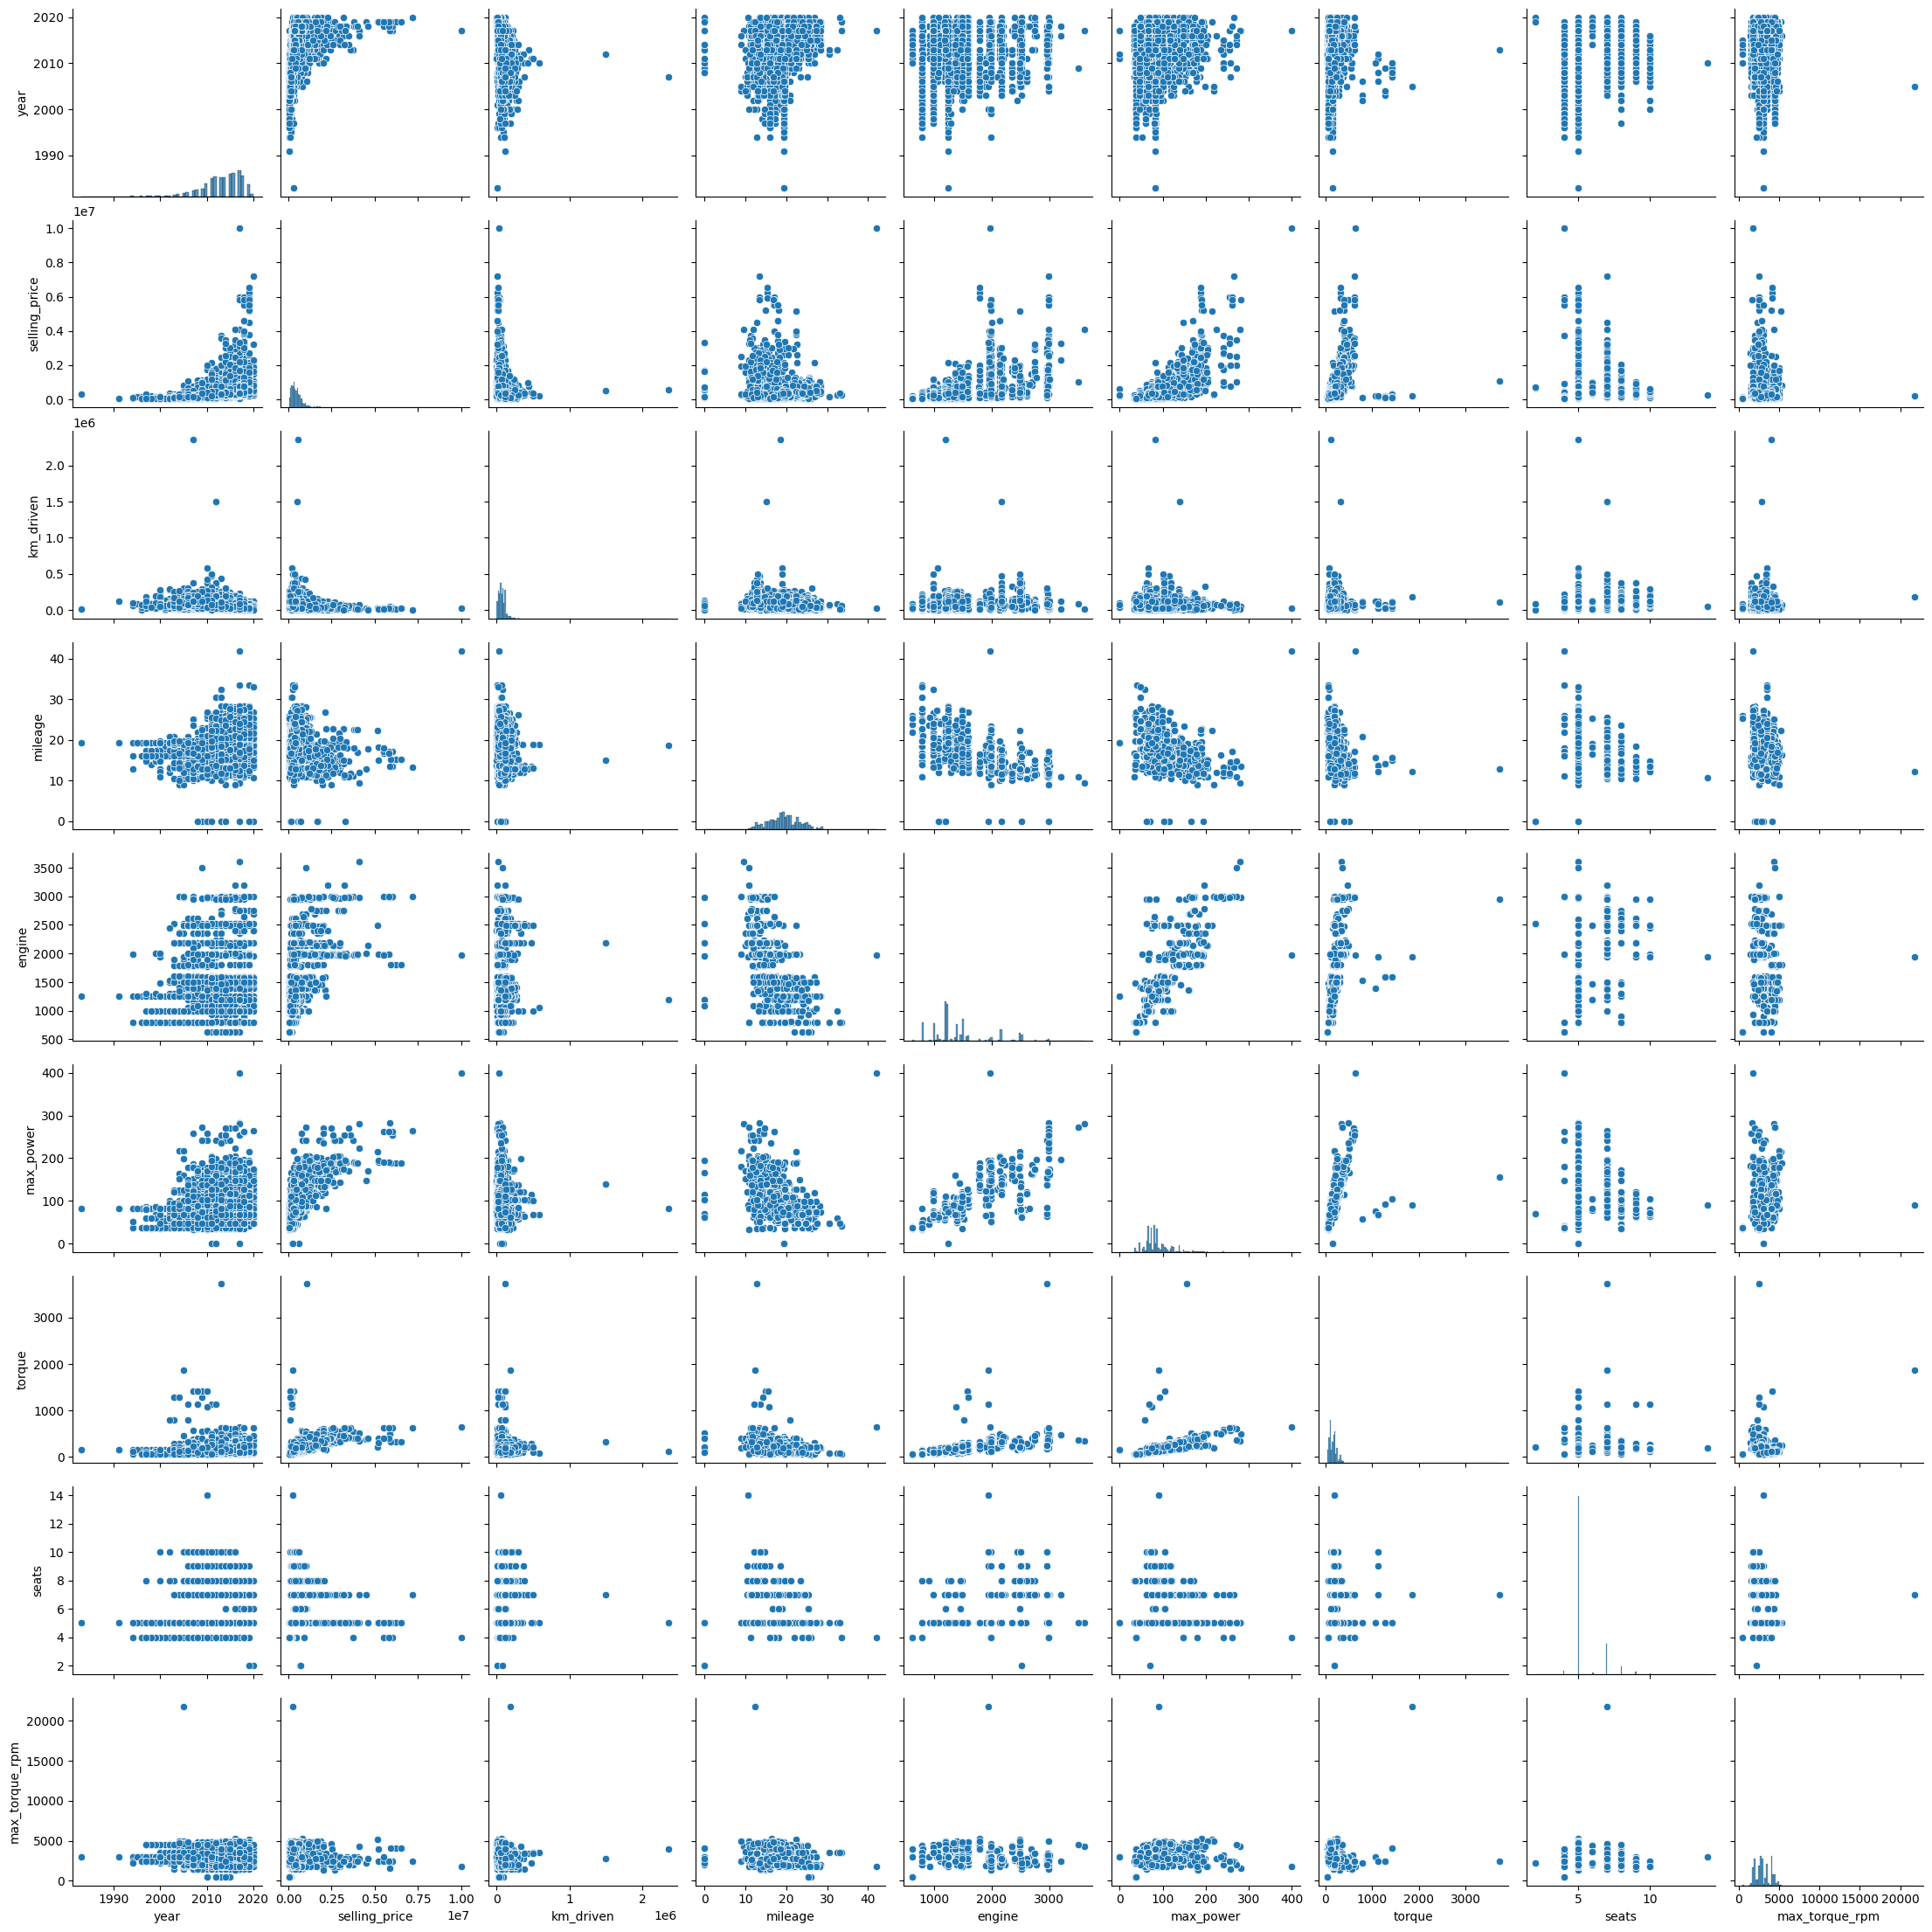

In [21]:
sns.pairplot(df_train.select_dtypes(include="number"))

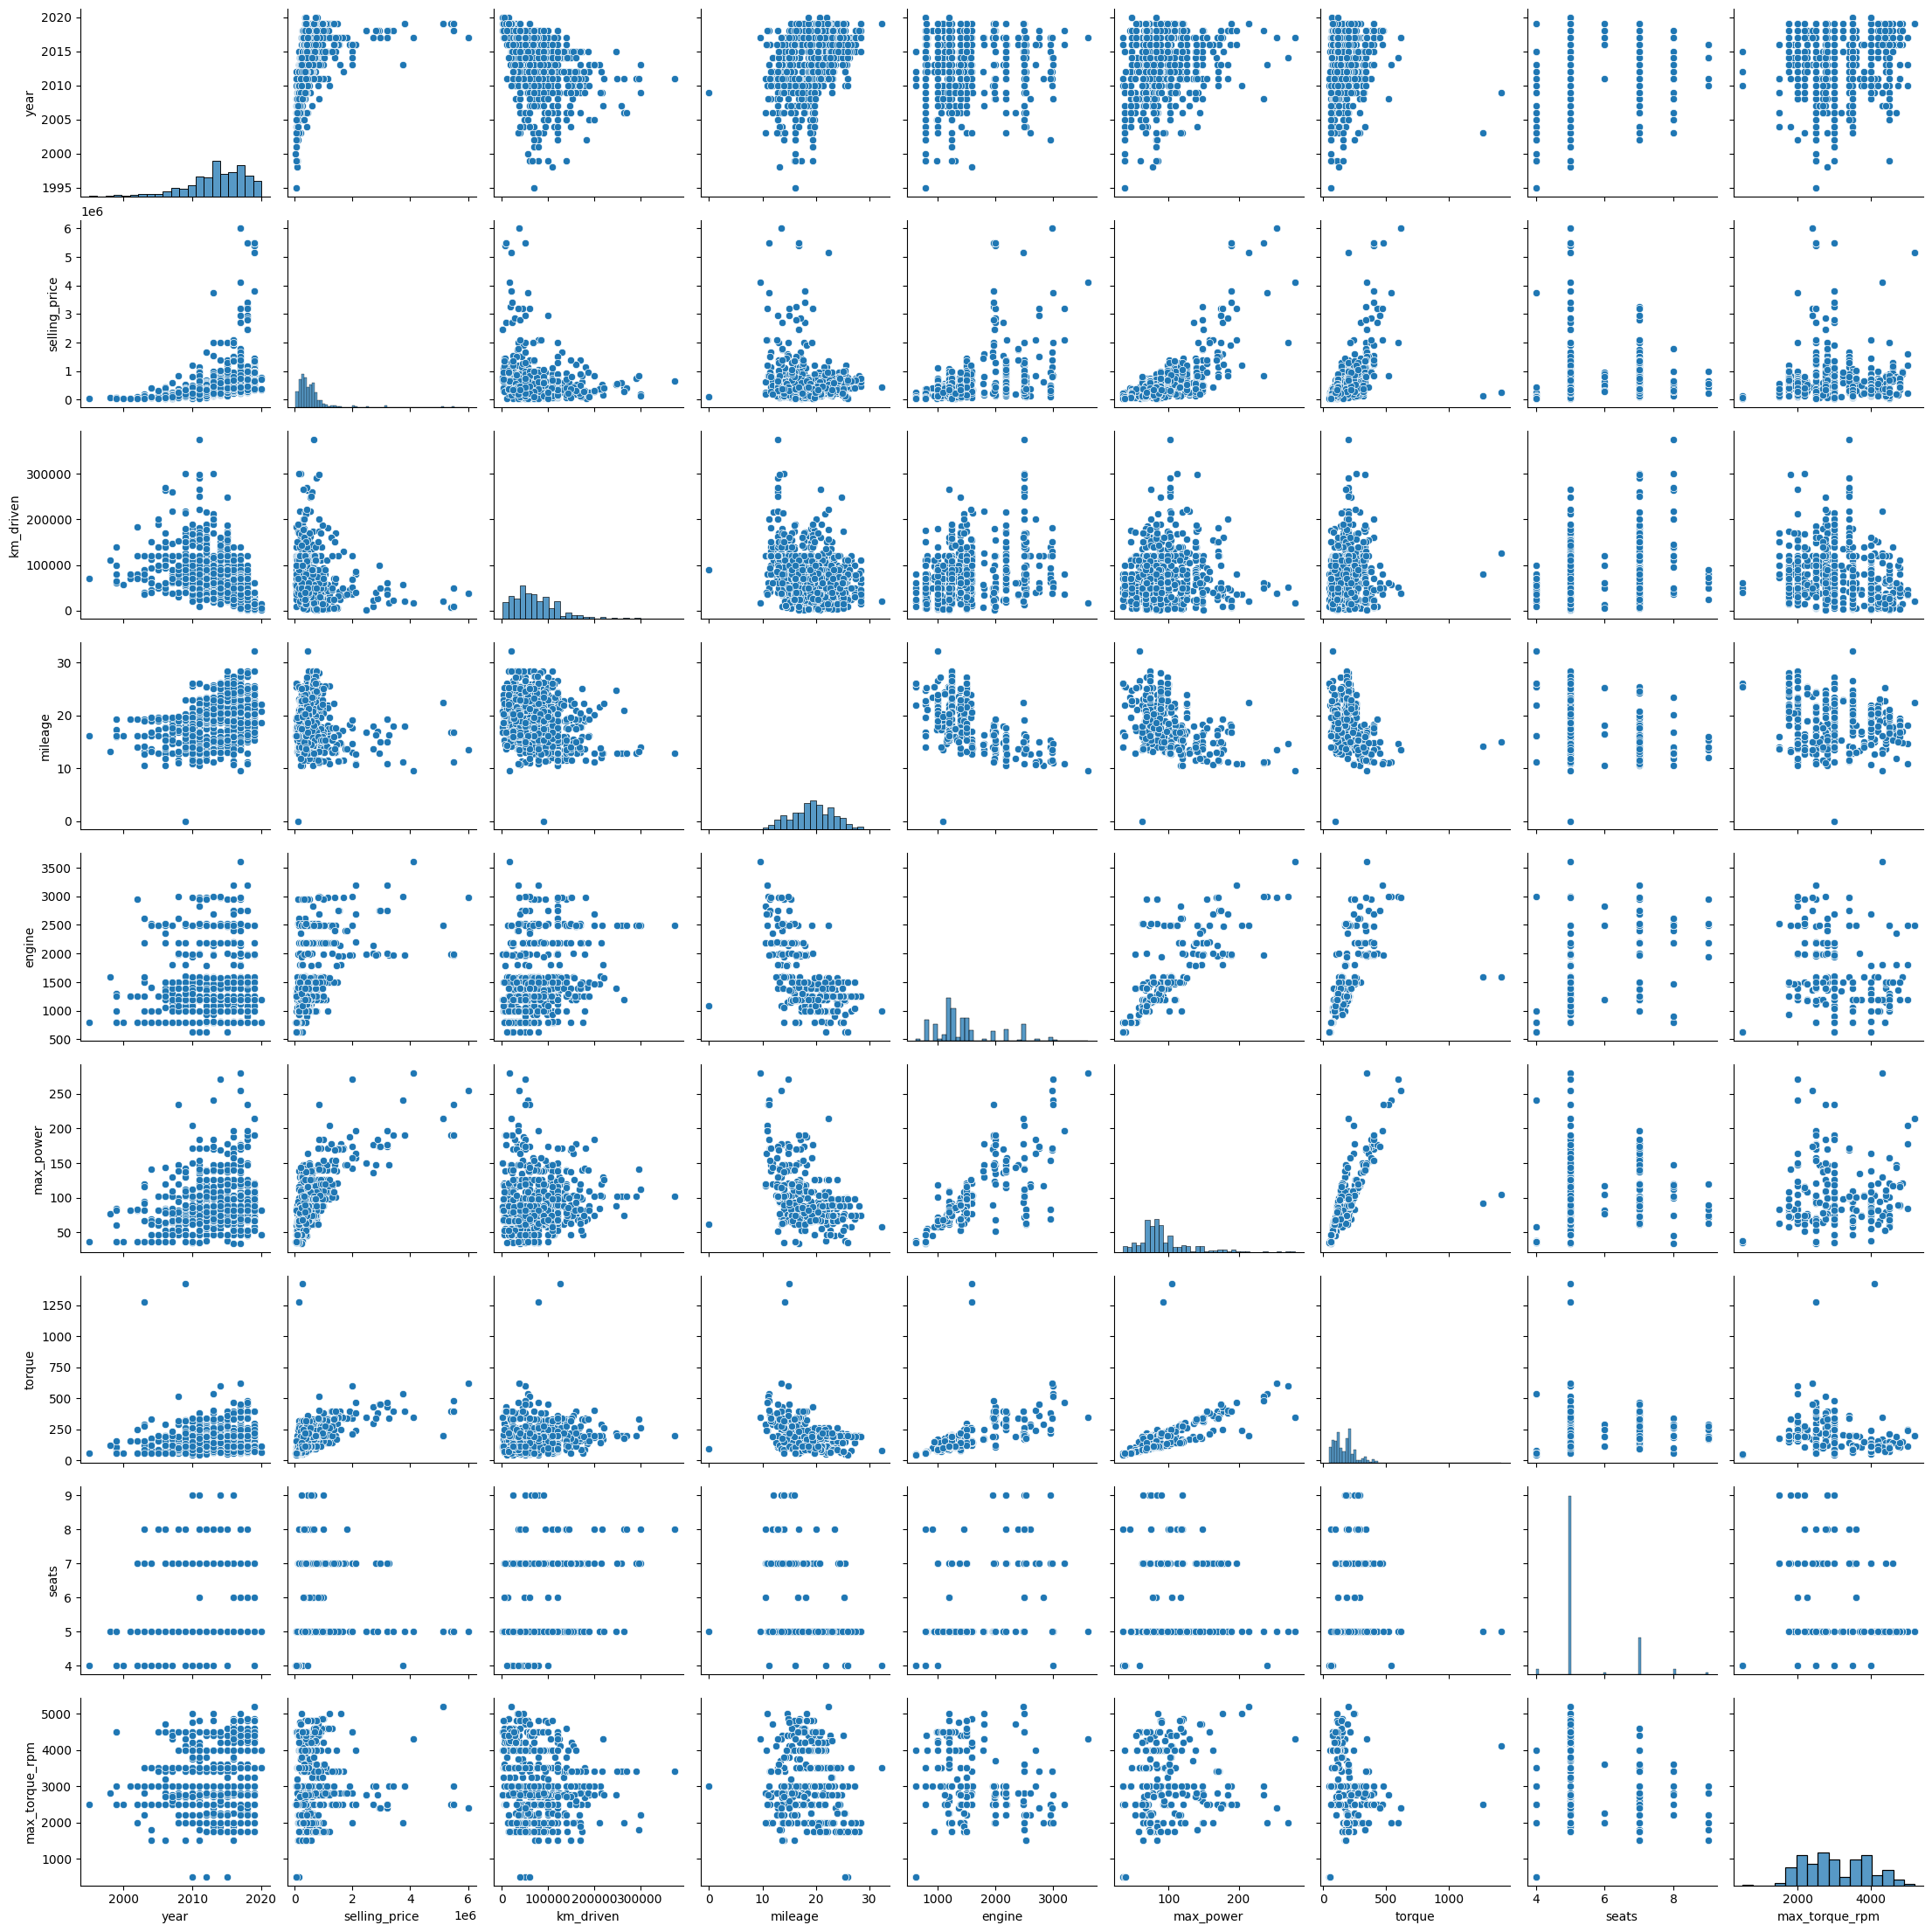

In [22]:
sns.pairplot(df_test.select_dtypes(include="number"))

`selling_price - выше при больших year, engine, max_power и torque. При большем km_driven цена ниже. Между engine, max_power, torque положительная связь. mileage уменьшается при росте engine и max_power.
Распределения и связи между признаками выглядят похоже у train и test`

### **Задание 9 (0.2 балла)**

Итак, вы выдвинули гипотезы о наличии связи. Теперь давайте оценим эту связь в числах.

**Задание:**
- [ ] Получите значения коэффициента корреляции Пирсона для тренировочного набора данных при помощи `DataFrame.corr()`
- [ ] По полученным корреляциям постройте тепловую карту (`heatmap` из библиотеки seaborn)

In [23]:
corr = df_train.corr(method="pearson", numeric_only=True)
corr

,year,selling_price,km_driven,mileage,engine,max_power,torque,seats,max_torque_rpm
year,1.000000,0.427279,-0.368966,0.341334,0.002819,0.156858,0.048388,0.041178,0.049746
selling_price,0.427279,1.000000,-0.164828,-0.104769,0.447672,0.692814,0.433318,0.149953,-0.082284
km_driven,-0.368966,-0.164828,1.000000,-0.182086,0.229766,0.024588,0.106585,0.192328,-0.199485
mileage,0.341334,-0.104769,-0.182086,1.000000,-0.572893,-0.373390,-0.226211,-0.451059,-0.189613
engine,0.002819,0.447672,0.229766,-0.572893,1.000000,0.681117,0.566209,0.652172,-0.232976
max_power,0.156858,0.692814,0.024588,-0.373390,0.681117,1.000000,0.616399,0.244112,-0.009728
torque,0.048388,0.433318,0.106585,-0.226211,0.566209,0.616399,1.000000,0.298165,-0.240837
seats,0.041178,0.149953,0.192328,-0.451059,0.652172,0.244112,0.298165,1.000000,-0.195842
max_torque_rpm,0.049746,-0.082284,-0.199485,-0.189613,-0.232976,-0.009728,-0.240837,-0.195842,1.000000


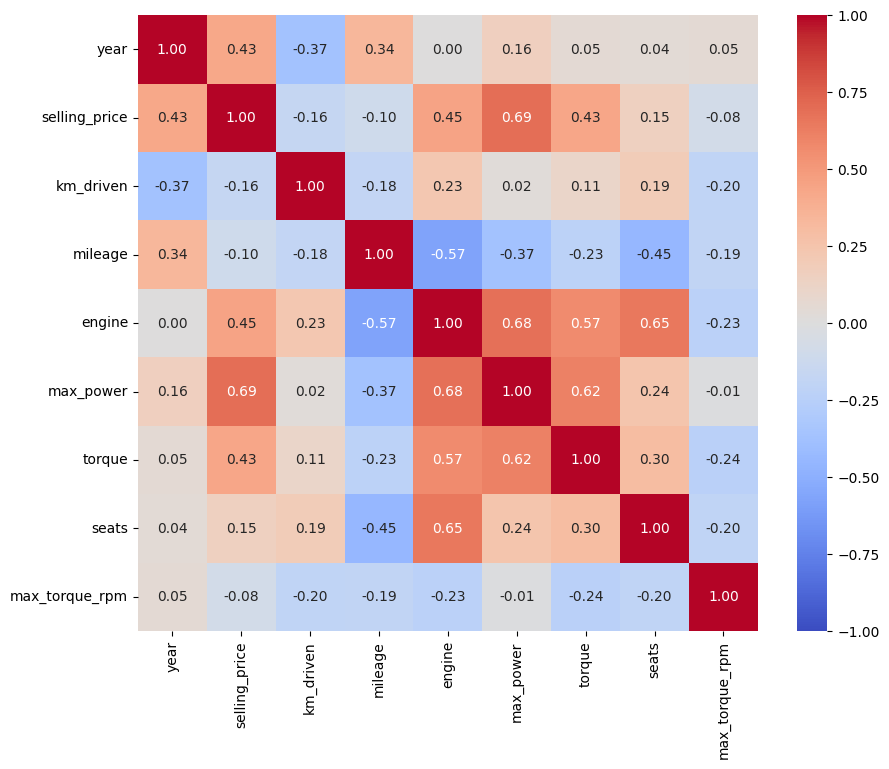

In [24]:
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.show()

- [ ] Ответьте на вопросы:
 - Какие 2 признака наименее скоррелированы между собой?
 - Между какими наблюдается довольно сильная положительная линейная зависимость?
 - Правильно ли, опираясь на данные, утверждать, что чем меньше год, тем, скорее всего, больше километров проехала машина к дате продажи?
 - Изучите типы корреляций в `DataFrame.corr()`. Какую вы использовали по умолчанию?

`year и engine не коррелируют. max_power и selling_price имеют корреляцию - 0.69, engine и seats - 0.65. Между km_driven и year корреляция -0.37, старые машины имеют больший пробег, но это справдливо не для каждой машины. Испльзовалась корреляция Пирсона, обычно берут ее, когда изучают корреляцию.`

### **Задание 10 (0.35 балла)**

По умолчанию `DataFrame.corr` возвращает корреляцию Пирсона, говорящую о линейной взаимосвязи. Но зависимости существуют не только линейные! В этой задаче, попробуйте другие способы вычисления корреляций.

- [ ] Реализуйте корреляцию Спирмена/Кендалла (на выбор) без использования библиотек (можно пользоваться только `numpy`). Сравните результаты вычисления с библиотечной реализацией
- [ ] Сделайте выводы


Постройте матрицу корреляции [phik](https://pypi.org/project/phik/)
- [ ] Проинтерпретируйте результаты

In [25]:
def ranks(x):
  _, inverse, counts = np.unique(x, return_inverse=True, return_counts=True)
  average_ranks = np.cumsum(counts) - (counts - 1) / 2
  return average_ranks[inverse]


def spearman(data):
  ranked = np.apply_along_axis(ranks, 0, data)
  centered = ranked - ranked.mean(axis=0)
  products = centered.T @ centered
  scale = np.sqrt(np.diag(products))
  return products / np.outer(scale, scale)

In [26]:
numeric = df_train.select_dtypes(include="number")

corr = pd.DataFrame(
  spearman(numeric.to_numpy()),
  index=numeric.columns,
  columns=numeric.columns
)
corr

,year,selling_price,km_driven,mileage,engine,max_power,torque,seats,max_torque_rpm
year,1.000000,0.707123,-0.569659,0.346132,-0.038056,0.165798,0.107395,0.048291,0.078423
selling_price,0.707123,1.000000,-0.295665,0.026186,0.463577,0.612258,0.583059,0.317605,-0.119402
km_driven,-0.569659,-0.295665,1.000000,-0.198466,0.304504,0.040919,0.238947,0.195317,-0.316573
mileage,0.346132,0.026186,-0.198466,1.000000,-0.429871,-0.308824,-0.155421,-0.435458,-0.183960
engine,-0.038056,0.463577,0.304504,-0.429871,1.000000,0.713113,0.839072,0.527716,-0.364073
max_power,0.165798,0.612258,0.040919,-0.308824,0.713113,1.000000,0.778326,0.304857,-0.017065
torque,0.107395,0.583059,0.238947,-0.155421,0.839072,0.778326,1.000000,0.433049,-0.522119
seats,0.048291,0.317605,0.195317,-0.435458,0.527716,0.304857,0.433049,1.000000,-0.190352
max_torque_rpm,0.078423,-0.119402,-0.316573,-0.183960,-0.364073,-0.017065,-0.522119,-0.190352,1.000000


In [27]:
corr = numeric.corr(method="spearman")
corr

,year,selling_price,km_driven,mileage,engine,max_power,torque,seats,max_torque_rpm
year,1.000000,0.707123,-0.569659,0.346132,-0.038056,0.165798,0.107395,0.048291,0.078423
selling_price,0.707123,1.000000,-0.295665,0.026186,0.463577,0.612258,0.583059,0.317605,-0.119402
km_driven,-0.569659,-0.295665,1.000000,-0.198466,0.304504,0.040919,0.238947,0.195317,-0.316573
mileage,0.346132,0.026186,-0.198466,1.000000,-0.429871,-0.308824,-0.155421,-0.435458,-0.183960
engine,-0.038056,0.463577,0.304504,-0.429871,1.000000,0.713113,0.839072,0.527716,-0.364073
max_power,0.165798,0.612258,0.040919,-0.308824,0.713113,1.000000,0.778326,0.304857,-0.017065
torque,0.107395,0.583059,0.238947,-0.155421,0.839072,0.778326,1.000000,0.433049,-0.522119
seats,0.048291,0.317605,0.195317,-0.435458,0.527716,0.304857,0.433049,1.000000,-0.190352
max_torque_rpm,0.078423,-0.119402,-0.316573,-0.183960,-0.364073,-0.017065,-0.522119,-0.190352,1.000000


In [28]:
!pip install phik

In [29]:
import phik

phik_corr = df_train.select_dtypes(include="number").phik_matrix()
phik_corr

interval columns not set, guessing: ['year', 'selling_price', 'km_driven', 'mileage', 'engine', 'max_power', 'torque', 'seats', 'max_torque_rpm']


,year,selling_price,km_driven,mileage,engine,max_power,torque,seats,max_torque_rpm
year,1.000000,0.219841,0.081574,0.279253,0.213156,0.381639,0.096307,0.288178,0.108330
selling_price,0.219841,1.000000,0.000000,0.649768,0.503682,0.872166,0.423431,0.196447,0.067457
km_driven,0.081574,0.000000,1.000000,0.081625,0.210747,0.000000,0.000000,0.096223,0.000000
mileage,0.279253,0.649768,0.081625,1.000000,0.588155,0.687235,0.204598,0.679979,0.391528
engine,0.213156,0.503682,0.210747,0.588155,1.000000,0.720780,0.466097,0.603400,0.467986
max_power,0.381639,0.872166,0.000000,0.687235,0.720780,1.000000,0.577329,0.569587,0.269920
torque,0.096307,0.423431,0.000000,0.204598,0.466097,0.577329,1.000000,0.206073,0.743877
seats,0.288178,0.196447,0.096223,0.679979,0.603400,0.569587,0.206073,1.000000,0.267162
max_torque_rpm,0.108330,0.067457,0.000000,0.391528,0.467986,0.269920,0.743877,0.267162,1.000000


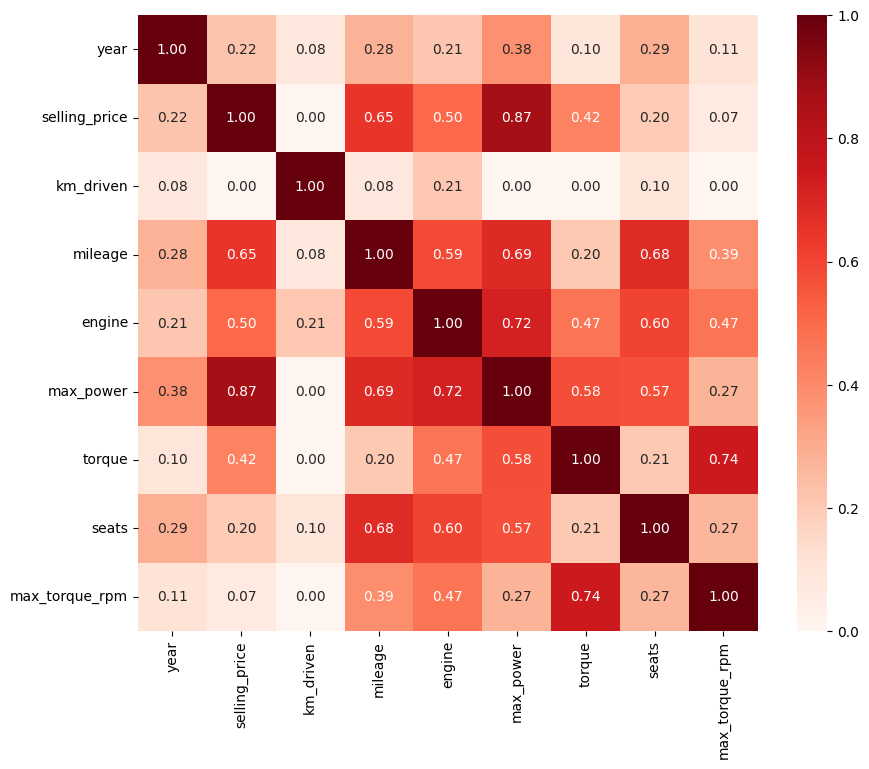

In [30]:
plt.figure(figsize=(10, 8))
sns.heatmap(phik_corr, annot=True, fmt=".2f", cmap="Reds", vmin=0, vmax=1)
plt.show()

`Моя реализация и библиотечная совпадают 1 в 1. selling_price - самая сильная связь с max_power - 0,87. engine и max_power - 0,72. torque и max_torque_rpm - 0.74, хотя у Пирсона было -0.24. mileage и selling_price - была -0.1, стало 0.65. В общем видно, что часть связей оказалась нелинейной. Единственный нюанс в том, что phik не показывает направление связи, только величину.`

### **Задание 11 (0.1 балла)**

Если вам кажется, что мы не попросили вас нарисовать какие-то очень важные зависимости, нарисуйте их **и поясните.**

- [ ] Постройте хотя бы одну дополнительную визуализацию и объясните, что она показывает и почему это важно.

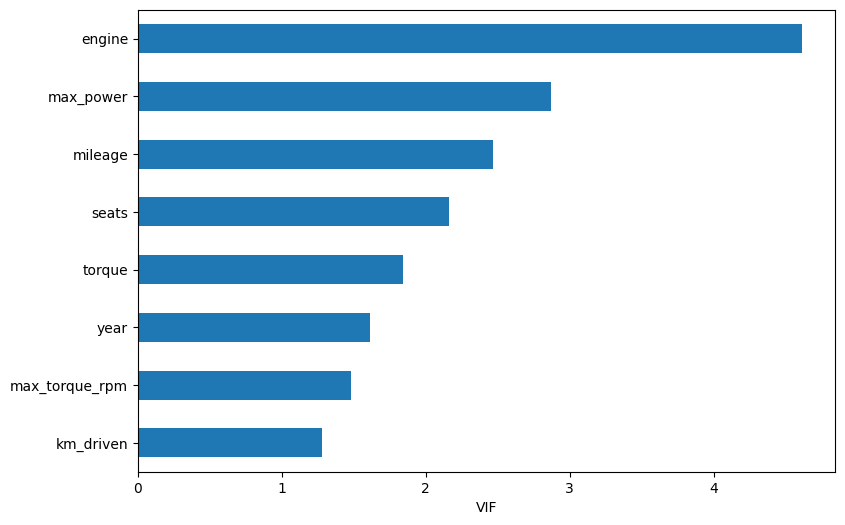

In [31]:
features = df_train.select_dtypes(include="number").drop(columns="selling_price")

vif = pd.Series(
  np.diag(np.linalg.inv(features.corr())),
  index=features.columns
)

vif.sort_values().plot.barh(figsize=(9, 6))
plt.xlabel("VIF")
plt.show()

`VIF показывает, насколько хорошо каждый признак можно выразить через остальные признаки вместе. Сильнее всего с остальными связан engine, затем max_power. Меньше всего связан km_driven (около 1,3). Это важно для модели, так как повторяющаяся информация может сделать модель менее стабильной.`

# **Часть 2 (1.4 балла) | Модель только на вещественных признаках**

В этой части вам предстоит обучить модель только на вещественных признаках. Почему только на них?

Чем больше признаковое пространство — тем сложнее модель. А чем модель проще — тем лучше для скорости работы и интерпретации признаков.

За задания этой части вы можете набрать 1.4 балла.

### **Задание 12 (0.05 балла)**

Сделайте тренировочный и тестовый наборы. Они уже даны, достаточно просто отделить целевой признак. Перед разбиением создайте копию датафрейма, который будет хранить только вещественные признаки и используйте его (то есть категориальные столбцы (все, кроме seats) необходимо удалить).

В переменные y_train и y_test запишите значения целевых переменных. Используйте уже имеющиеся данные train и test. Если считаете уместным применить какую-то более хитрую технику разбиения — примените, но опишите, зачем.

In [32]:
train_numeric = df_train.select_dtypes(include="number").copy()

y_train = train_numeric["selling_price"]
X_train = train_numeric.drop(columns="selling_price")

In [33]:
# year - год выпуска
# km_driven - пробег
# mileage - расстояние на единицу топлива
# engine - объём двигателя
# max_power - максимальная мощность
# torque - крутящий момент
# seats - количество мест
# max_torque_rpm - максимальные обороты

In [34]:
test_numeric = df_test.select_dtypes(include="number").copy()

y_test = test_numeric["selling_price"]
X_test = test_numeric.drop(columns="selling_price")

### **Задание 13 (0.2 балла)**

Построим нашу первую модель!
- [ ] Обучите классическую линейную регрессию с дефолтными параметрами. Посчитайте $R^2$ и $MSE$ для трейна и для теста.
- [ ] Сделайте выводы по значениям метрик качества.

**Примечание:**

Здесь и далее $R^2$ и $MSE$ для трейна и для теста выводите везде, где требуется обучать модели, даже если в явном виде этого не просят. Иначе непонятно, как понять, насколько успешны наши эксперименты.

In [35]:
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [36]:
pred_train = model.predict(X_train)
pred_test = model.predict(X_test)

In [37]:
r2_score(y_train, pred_train), r2_score(y_test, pred_test), MSE(y_train, pred_train), MSE(y_test, pred_test)

(0.6012026801206398,
 0.6007494611703509,
 114310601111.79837,
 229500610573.31784)

R² на train и test почти одинаковый - ~0.60. MSE на тесте сильно выше почти вдвое, чем на трейне

### **Задание 14 (0.25 балла)**

**Шаг 1 (0.15 балла)**
- [ ] Реализуйте $R^2$ руками. Приведите формулу $R^2$ и объясните каждую компоненту метрики

In [38]:
def r2(y_true, y_pred):
  errors = np.sum((y_true - y_pred) ** 2)
  total = np.sum((y_true - np.mean(y_true)) ** 2)
  return 1 - errors / total

- y_i - настоящее значение
- y_hat_i - предсказание модели
- y_mean - среднее настоящих значений
- n - число объектов
- errors - сумма квадратов ошибок
- total - сумма квадратов отклонений от среднего

**Шаг 2 (0.1 балла)**

- [ ] Реализуйте [$\text{adjusted}-R^2$](https://en.wikipedia.org/wiki/Coefficient_of_determination).
- [ ] Объясните, когда применяется $\text{adjusted}-R^2$?

In [39]:
def adjusted_r2(y_true, y_pred, p):
  n = len(y_true)
  r2_ = r2(y_true, y_pred)
  return 1 - (1 - r2_) * (n - 1) / (n - p - 1)

`Adjusted R2 учитывает число признаков. Его используют для сравнения линейных моделей. Если добавить какой-то вредный признак, adjusted R2 снизится.`

### **Задание 15 (0.05 балла)**

Всегда есть место совершенству. Поэтому давайте попробуем улучшить модель при помощи стандартизации признаков.

- [ ] Стандартизируйте значения в тренировочных и тестовых данных. Стандартизатор **обучайте только на `train`**.

In [40]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [41]:
model = LinearRegression()
model.fit(X_train_scaled, y_train)

LinearRegression()

In [42]:
pred_train = model.predict(X_train_scaled)
pred_test = model.predict(X_test_scaled)

In [43]:
r2_score(y_train, pred_train), r2_score(y_test, pred_test), MSE(y_train, pred_train), MSE(y_test, pred_test)

(0.6012026801206402,
 0.6007494611703506,
 114310601111.79826,
 229500610573.31805)

### **Задание 16 (0.1 балла)**

Хотя стандартизация не помогла сильно прибавить в качестве, она открыла возможность интерпретировать важность признаков в модели. Правило интерпретации такое:

Чем больше коэффициент $\beta_i$ по модулю, тем важнее признак.

**Ответьте на вопрос:**

- [ ] Какой признак оказался наиболее информативным в предсказании цены?

In [44]:
pd.Series(model.coef_, index=X_train.columns).sort_values(key=abs, ascending=False)

,0
max_power,331300.384565
year,165614.378862
max_torque_rpm,-59822.512703
km_driven,-48759.912082
seats,-29817.949376
engine,22789.076161
mileage,-8487.443672
torque,4622.571038


`max_power`

### **Задание 17 (0.2 балла)**

Попробуем улучшить нашу модель с помощью применения регуляризации. Для этого воспользуемся `Lasso` регрессией.  Кроме того, попробуйте использовать её теоретическое свойство отбора признаков, за счет зануления незначимых коэффициентов.

**Задание:**

- [ ] Обучите Lasso регрессию на тренировочном наборе данных со стандартизованными признаками. Оцените её качество
- [ ] Проверьте, занулила ли L1-регуляризация с параметрами по умолчанию какие-нибудь веса? Предположите почему.

In [45]:
lasso = Lasso()
lasso.fit(X_train_scaled, y_train)

Lasso()

In [46]:
pred_train = lasso.predict(X_train_scaled)
pred_test = lasso.predict(X_test_scaled)

In [47]:
r2_score(y_train, pred_train), r2_score(y_test, pred_test), MSE(y_train, pred_train), MSE(y_test, pred_test)

(0.601202680073043, 0.6007481715596676, 114310601125.44144, 229501351878.36426)

In [48]:
pd.Series(lasso.coef_, index=X_train.columns).sort_values(key=abs, ascending=False)

,0
max_power,331301.745031
year,165612.175388
max_torque_rpm,-59820.423512
km_driven,-48758.977510
seats,-29813.981980
engine,22787.068243
mileage,-8484.152921
torque,4621.934744


`Ни один коэффициент не занулился. Скорее всего из-за большого масштаба таргета регуляризация работает слишком слабо.`

### **Задание 18. Финальный рывок (0.3 балла)**

До этого мы с вами использовали `train` для обучения и `test` для прогнозирования. Но у нас есть ещё одна задача — подобрать оптимальные параметры модели. Для этого используем кросс-валидацию, описанную на семинарах.

Кроме того, выжмем максимум из модификаций регрессии. Построим `ElasticNet`. И сделаем всё по порядку.

**Ваша задача 1:**

- [ ] Перебором по сетке (с 10 фолдами) подберите оптимальные параметры для Lasso-регрессии. Вам пригодится класс [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html).
- [ ] Ответьте на вопросы:
 - Сколько грид-сёрчу пришлось обучать моделей?
 - Что значит каждый параметр `param_grid`, который вы заполняли для `GridSearch`? Опишите каждый
 - Какой коэффициент регуляризации у лучшей из перебранных моделей? Занулились ли какие-нибудь из весов при такой регуляризации?

In [49]:
alphas = np.logspace(-2, 6, 9)

In [50]:
from sklearn.pipeline import make_pipeline

In [51]:
lasso_search = GridSearchCV(
  make_pipeline(StandardScaler(), Lasso(max_iter=10000)),
  param_grid={"lasso__alpha": alphas},
  cv=10,
  scoring="neg_mean_squared_error"
)

lasso_search.fit(X_train, y_train)

GridSearchCV(cv=10,
             estimator=Pipeline(steps=[('standardscaler', StandardScaler()),
                                       ('lasso', Lasso(max_iter=10000))]),
             param_grid={'lasso__alpha': array([1.e-02, 1.e-01, 1.e+00, 1.e+01, 1.e+02, 1.e+03, 1.e+04, 1.e+05,
       1.e+06])},
             scoring='neg_mean_squared_error')

In [52]:
lasso_search.best_params_

{'lasso__alpha': np.float64(1000.0)}

In [53]:
weights = lasso_search.best_estimator_["lasso"].coef_
pd.Series(weights, index=X_train.columns).sort_values(key=abs, ascending=False)

,0
max_power,332652.240992
year,163303.971522
max_torque_rpm,-57663.348381
km_driven,-47850.726993
seats,-25826.430185
engine,20921.333478
mileage,-5016.064824
torque,3978.681010


In [54]:
pred_train = lasso_search.predict(X_train)
pred_test = lasso_search.predict(X_test)

r2_score(y_train, pred_train), r2_score(y_test, pred_test), MSE(y_train, pred_train), MSE(y_test, pred_test)

(0.6011534797671076, 0.5994331152038028, 114324703819.38147, 230257283823.9892)

Обучено 90 моделей, лучшую модель обучили на всем трейн еще раз. Перебор был по lasso__alpha - сила регуляризации. Лучшее значение 10^3. Веса не занулились, но стали ниже, чем были на дефолтном Лассо.

**Ваша задача 2:**

- [ ] Перебором по сетке (с 10 фолдами) подберите оптимальные параметры для [ElasticNet](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.ElasticNet.html) регрессии.
- [ ] Ответьте на вопросы:
 - Сколько грид-сёрчу пришлось обучать моделей?
 - Какие гиперпараметры соответствуют лучшей (по выбранной метрике качества) из перебранных моделей?

In [55]:
elastic_search = GridSearchCV(
  make_pipeline(StandardScaler(), ElasticNet(max_iter=10000)),
  param_grid={
      "elasticnet__alpha": alphas,
      "elasticnet__l1_ratio": [0.1, 0.5, 0.9, 1.0]
    },
  cv=10,
  scoring="neg_mean_squared_error"
)

elastic_search.fit(X_train, y_train)

GridSearchCV(cv=10,
             estimator=Pipeline(steps=[('standardscaler', StandardScaler()),
                                       ('elasticnet',
                                        ElasticNet(max_iter=10000))]),
             param_grid={'elasticnet__alpha': array([1.e-02, 1.e-01, 1.e+00, 1.e+01, 1.e+02, 1.e+03, 1.e+04, 1.e+05,
       1.e+06]),
                         'elasticnet__l1_ratio': [0.1, 0.5, 0.9, 1.0]},
             scoring='neg_mean_squared_error')

In [56]:
elastic_search.best_params_

{'elasticnet__alpha': np.float64(1000.0), 'elasticnet__l1_ratio': 1.0}

In [57]:
pred_train = elastic_search.predict(X_train)
pred_test = elastic_search.predict(X_test)

r2_score(y_train, pred_train), r2_score(y_test, pred_test), MSE(y_train, pred_train), MSE(y_test, pred_test)

(0.6011534797671076, 0.5994331152038028, 114324703819.38147, 230257283823.9892)

Обучено 360 моделей + самая оптимальная на всем трейне. Лучшие параметры alpha = 10^3, l1_ratio = 1.0.

### **Задание 19 (0.25 балла)**

Итак, вы обучили все варианты регуляризаций, доступные в sklearn, но не все, что мы обсудили на занятии! Следующее задание — о забытой $L0$-регуляризации.

Задача линейной регрессии с $L0$-регуляризацией:

$$\min_{w}\; \frac{1}{n}\|y - Xw\|_2^2 + \lambda \|w\|_0, \qquad \|w\|_0 = \#\{j : w_j \neq 0\}.$$

Штраф $\|w\|_0$ разрывный и невыпуклый, поэтому градиентным спуском «в лоб» задачу не решить. **Выберите один** из способов (или предложите свой и обоснуйте его):

1. **Полный перебор подмножеств (best subset selection).** Для каждого подмножества признаков $S$ обучите МНК только на признаках из $S$ (веса $\hat w_S$) и выберите
$$S^* = \arg\min_{S}\; \frac{1}{n}\|y - X_S \hat w_S\|_2^2 + \lambda |S|.$$
Перебор $2^d$ подмножеств реален при небольшом числе признаков $d$ (у нас вещественных признаков меньше десяти).

2. **Жадный отбор (forward / backward stepwise).** Начните с пустого (полного) набора признаков и на каждом шаге добавляйте (удаляйте) тот признак, который сильнее всего уменьшает $\frac{1}{n}\|y - X_S \hat w_S\|_2^2 + \lambda |S|$. Остановитесь, когда функционал перестанет уменьшаться.

3. **Iterative Hard Thresholding (проксимальный градиентный спуск).** Сделайте шаг градиентного спуска по MSE с шагом $\eta$, затем занулите малые веса:
$$z = w^{(t)} - \eta\, \nabla_w \tfrac{1}{n}\|y - Xw^{(t)}\|_2^2, \qquad w^{(t+1)}_j = z_j \cdot \mathbb{1}\left[|z_j| > \sqrt{2\eta\lambda}\right].$$

4. **Стохастические «ворота» с hard concrete распределением** ([Louizos et al., 2018](https://arxiv.org/abs/1712.01312)). Веса параметризуются как $w = \tilde w \odot z$, где $z_j \in [0, 1]$:
$$u_j \sim U(0,1),\quad s_j = \sigma\!\left(\frac{\log u_j - \log(1-u_j) + \log\alpha_j}{\beta}\right),\quad z_j = \min\big(1, \max(0,\, s_j(\zeta-\gamma)+\gamma)\big),$$
а недифференцируемый $\|w\|_0$ заменяется на его матожидание $\sum_j P(z_j \neq 0)$:
$$\min_{\tilde w,\, \log\alpha}\; \mathbb{E}_u\!\left[\frac{1}{n}\|y - X(\tilde w \odot z)\|_2^2\right] + \lambda\sum_{j}\sigma\!\left(\log\alpha_j - \beta\log\frac{-\gamma}{\zeta}\right).$$
Типичные значения: $\beta = \frac{2}{3},\ \gamma = -0.1,\ \zeta = 1.1$. Оптимизируйте градиентным спуском (например, в PyTorch). На инференсе используйте детерминированные ворота $z_j = \min\big(1, \max(0,\, \sigma(\log\alpha_j)(\zeta-\gamma)+\gamma)\big)$.

Для способов 3 и 4 признаки должны быть стандартизованы.

**Ваша задача:**
- [ ] Реализуйте модель с $L0$-регуляризацией одним из способов выше.
- [ ] Обучите модель при нескольких значениях $\lambda$ и проанализируйте, как меняются число ненулевых весов и качество ($R^2$ и $MSE$ на трейне и тесте).

**Важно:**

Несмотря на то что L0 не реализована в стандартных пакетах, концепция данной регуляризации не является мертвой. Она встречается в статьях и экспериментах.

In [58]:
from itertools import product

train = np.column_stack([np.ones(len(X_train)), X_train_scaled])
test = np.column_stack([np.ones(len(X_test)), X_test_scaled])

candidates = []

for mask in product([False, True], repeat=X_train.shape[1]):
  columns = np.array([True, *mask])
  weights = np.zeros(train.shape[1])

  weights[columns] = np.linalg.lstsq(
      train[:, columns], y_train, rcond=None
  )[0]

  error = MSE(y_train, train @ weights)
  candidates.append((error, weights))

In [59]:
results = []

for alpha in [1e8, 1e9, 1e10, 1e11, 1e12]:
  error, weights = min(
      candidates,
      key=lambda item: item[0] + alpha * np.count_nonzero(item[1][1:])
  )

  pred_train = train @ weights
  pred_test = test @ weights

  results.append({
      "lambda": alpha,
      "nonzero": np.count_nonzero(weights[1:]),
      "R2_train": r2_score(y_train, pred_train),
      "R2_test": r2_score(y_test, pred_test),
      "MSE_train": MSE(y_train, pred_train),
      "MSE_test": MSE(y_test, pred_test)
  })

results

[{'lambda': 100000000.0,
  'nonzero': np.int64(6),
  'R2_train': 0.6010699937314573,
  'R2_test': 0.6006608897191832,
  'MSE_train': 114348634117.91635,
  'MSE_test': 229551523972.6634},
 {'lambda': 1000000000.0,
  'nonzero': np.int64(4),
  'R2_train': 0.5997396881219319,
  'R2_test': 0.5968025593656685,
  'MSE_train': 114729950707.33887,
  'MSE_test': 231769402436.9502},
 {'lambda': 10000000000.0,
  'nonzero': np.int64(2),
  'R2_train': 0.5840614392693603,
  'R2_test': 0.5813165160854106,
  'MSE_train': 119223937906.80145,
  'MSE_test': 240671222328.29532},
 {'lambda': 100000000000.0,
  'nonzero': np.int64(1),
  'R2_train': 0.47999126828565986,
  'R2_test': 0.5127654012878643,
  'MSE_train': 149054438790.1905,
  'MSE_test': 280076360634.77405},
 {'lambda': 1000000000000.0,
  'nonzero': np.int64(0),
  'R2_train': 0.0,
  'R2_test': -0.01568082182097763,
  'MSE_train': 286638338357.88654,
  'MSE_test': 583842339797.0208}]

Чем выше lambda, тем меньше ненулевых весов. lambda = 10^8 самая оптимальная, убрали 2 признака, при этом почти не просели в качестве.

# **Часть 3 (0.5 балла) | Добавляем категориальные фичи**

Попробуем для улучшения модели дать ей больше признаков. Добавим категориальные фичи.

За эту часть можно набрать 0.5 балла.

### **Задание 20 (0.1 балла)**

Проанализируйте столбец `name`. Очевидно, что эта переменная является категориальной, однако категорий в ней много.

- [ ] Создайте `X_train_cat` и `X_test_cat` — копии `df_train` и `df_test` без целевой переменной (со всеми признаками, включая категориальные)
- [ ] Предобработайте столбец `name`, чтобы избежать его удаления

In [60]:
X_train_cat = df_train.drop(columns="selling_price").copy()
X_train_cat["name"] = X_train_cat["name"].str.split().str[0]

X_test_cat = df_test.drop(columns="selling_price").copy()
X_test_cat["name"] = X_test_cat["name"].str.split().str[0]

In [61]:
# 14 столбцов после разбиения torque, минус selling_price; name предобработан в один столбец.
# Если из name получилось несколько столбцов — скорректируйте ожидаемую размерность.
assert X_train_cat.shape == (5840, 13)

In [62]:
X_train_cat.describe(include='object')

,name,fuel,seller_type,transmission,owner
count,5840,5840,5840,5840,5840
unique,30,4,3,2,5
top,Maruti,Diesel,Individual,Manual,First Owner
freq,1804,3177,5223,5336,3603


### **Задание 21 (0.1 балла)**

- [ ] Закодируйте категориальные фичи и ``seats`` методом OneHot-кодирования.

In [63]:
from sklearn.compose import ColumnTransformer

cat_columns = ["name", "fuel", "seller_type", "transmission", "owner", "seats"]

encoder = ColumnTransformer(
    [("ohe", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), cat_columns)],
    remainder="passthrough"
)

encoder.fit(X_train_cat)

X_train_encoded = encoder.transform(X_train_cat)
X_test_encoded = encoder.transform(X_test_cat)

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


### **Задание 22 (0.2 балла)**

OHE — базовый алгоритм преобразования категориальных признаков, но и с ним нужно быть аккуратными.

**Ответьте на вопросы:**


* Как корректно работать с OHE преобразованием?
* Почему мы удаляем один столбец?
* Пусть из категориального признака с $n$ категориями мы получили $n-1$ столбец, из которых $k < n-1$ оказались неважными по весам модели. Корректно ли их удалить?

`OHE фитим только на train, затем этим же кодировщиком преобразуем train и test.В линейной регрессии полный набор OHE-столбцов создаёт линейную зависимость (столбцы всегда в сумме дают 1), поэтому убираем первый столбец. Коэффицент при категории значит ее отличие от первого в комбинации, так что по сути удаление эквивалентно слиянию, модель перестанет различать случаи, где остальные признаки ожинаковы, а эти категории отличаются.`

### **Задание 23 (0.1 балла)**
Повторим то, что делали на прошлом шаге для моделей на вещественных признаках, однако теперь с моделью `Ridge`.


**Ваша задача:**
- [ ] Переберите параметр регуляризации `alpha` для гребневой (ridge) регрессии с помощью класса `GridSearchCV`. В качестве параметров при объявлении GridSearchCV кроме модели укажите метрику качества $R^2$. Кроссвалидируйтесь по 10-ти фолдам.
- [ ] Ответьте на вопрос: Удалось ли улучшить качество прогнозов?

In [64]:
ridge_search = GridSearchCV(
    make_pipeline(encoder, StandardScaler(), Ridge()),
    param_grid={"ridge__alpha": alphas},
    cv=10,
    scoring="r2"
)

ridge_search.fit(X_train_cat, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categ

GridSearchCV(cv=10,
             estimator=Pipeline(steps=[('columntransformer',
                                        ColumnTransformer(remainder='passthrough',
                                                          transformers=[('ohe',
                                                                         OneHotEncoder(drop='first',
                                                                                       handle_unknown='ignore',
                                                                                       sparse_output=False),
                                                                         ['name',
                                                                          'fuel',
                                                                          'seller_type',
                                                                          'transmission',
                                                                          'owner',
                                                                          'seats'])])),
                                       ('standardscaler', StandardScaler()),
                                       ('ridge', Ridge())]),
             param_grid={'ridge__alpha': array([1.e-02, 1.e-01, 1.e+00, 1.e+01, 1.e+02, 1.e+03, 1.e+04, 1.e+05,
       1.e+06])},
             scoring='r2')

In [65]:
ridge_search.best_params_

{'ridge__alpha': np.float64(1000.0)}

In [66]:
pred_train = ridge_search.predict(X_train_cat)
pred_test = ridge_search.predict(X_test_cat)

r2_score(y_train, pred_train), r2_score(y_test, pred_test), MSE(y_train, pred_train), MSE(y_test, pred_test)

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


(0.7656549624563367, 0.7761298668810983, 67172272163.93221, 128686945271.3245)

Лучшее значение alpha = 10^3. Качество выросло R2: 0.60 -> 0.78, MSE: ~230 млрд -> ~129 млрд.

# **Часть 4 (0.4 балла) | Feature Engineering**

### **Задание 24 (0.4 балла)**

В этой части домашнего задания вам предлагается проявить свою креативность для улучшения прогноза модели. Любые другие модели, кроме различных форм линейной (или полиномиальной) регрессии, использовать запрещается. А значит, придется работать с признаками

**Что можно попробовать сделать?** (каждый пункт — до 0.2 балла, но не больше 0.4 балла в сумме)

1.   *Сгенерировать новые признаки на основе уже существующих:*
    * посчитать произведения // частные признаков (кажется, что посчитать число "лошадей" на литр объема может быть полезно);
    * имеет смысл обратить внимание на визуализации в части с EDA (к примеру, зависимость цены от года выглядит квадратичной, а не линейной; значит, квадрат года нам, скорее всего, принесет больше пользы)

2.   *Добыть новые признаки:*
    * из названия автомобиля можно извлечь больше информации (например, спарсить инфу о классе автомобиля или каких-то специфических опциях)
    * можно добавить пороговые признаки вроде "владелец третий или больше" и объединить признаки в некоторые осмысленные правила, например "первый или второй владелец и продавец официальный дилер" (подбирать пороги удобно по диаграммам рассеяния)

3.   *Поработать с уже имеющимися:*
    * далеко не факт, что заполнить пропуск медианой было лучшей идеей (как минимум, можно добавить dummy-столбец для модели, сигнализирующий, что раньше на месте медианы был пропуск -- там где он был, конечно); попробуйте другие способы филлинга;
    * мы не анализировали, есть ли в данных выбросы => никак выбросы не обрабатывали; наиболее простым и, тем не менее, довольно полезным вариантом нахождения выбросов могут послужить boxplot'ы для каждого столбца; что делать с выбросами думайте сами :) -- вариантов довольно много
    * мы толком не смотрели на таргет сам по себе; в нем тоже могут быть неожиданности -- стоит хотя бы проверить
    * можно заметить, что некоторые признаки распределены совсем не нормально; возможно их стоит отлогарифмировать

И так далее...

Feel Free to Try!

In [67]:
models = (
    "swift dzire|wagon r|grand i10|alto k10|alto 800|"
    "santro xing|land cruiser|vitara brezza|innova crysta|"
    "elite i20|figo aspire|safari storme|grand vitara|"
    "corolla altis|range rover|[1-8] series|new c-class"
)

pattern = rf"^((?:land rover|ashok leyland|\S+)\s+(?:{models}|\S+))(?=\s|$)"

In [68]:
X_train_feature_engineering = X_train_cat.copy()
X_test_feature_engineering = X_test_cat.copy()

X_train_feature_engineering["model_name"] = df_train["name"].str.lower().str.extract(pattern, expand=False)
X_test_feature_engineering["model_name"] = df_test["name"].str.lower().str.extract(pattern, expand=False)

In [69]:
cat_columns = ["name", "fuel", "seller_type", "transmission", "owner", "seats", "model_name"]

encoder = ColumnTransformer(
    [("ohe", OneHotEncoder(
        drop="first",
        handle_unknown="ignore",
        sparse_output=False
    ), cat_columns)],
    remainder="passthrough"
)

In [70]:
# max_power и mileage на phik показали высокую связь. Также на phik видна связь max_torque_rpm и torque, добавим их проиведение. engine и max_power на корреляции Пирсона имели высокую связанность.

for df in [X_train_feature_engineering, X_test_feature_engineering]:
    df["max_power_squared"] = df["max_power"] ** 2

for df in [X_train_feature_engineering, X_test_feature_engineering]:
    df["mileage_squared"] = df["mileage"] ** 2

for df in [X_train_feature_engineering, X_test_feature_engineering]:
    df["power_per_liter"] = df["max_power"] / (df["engine"] / 1000)

for df in [X_train_feature_engineering, X_test_feature_engineering]:
    df["torque_rpm"] = df["torque"] * df["max_torque_rpm"]

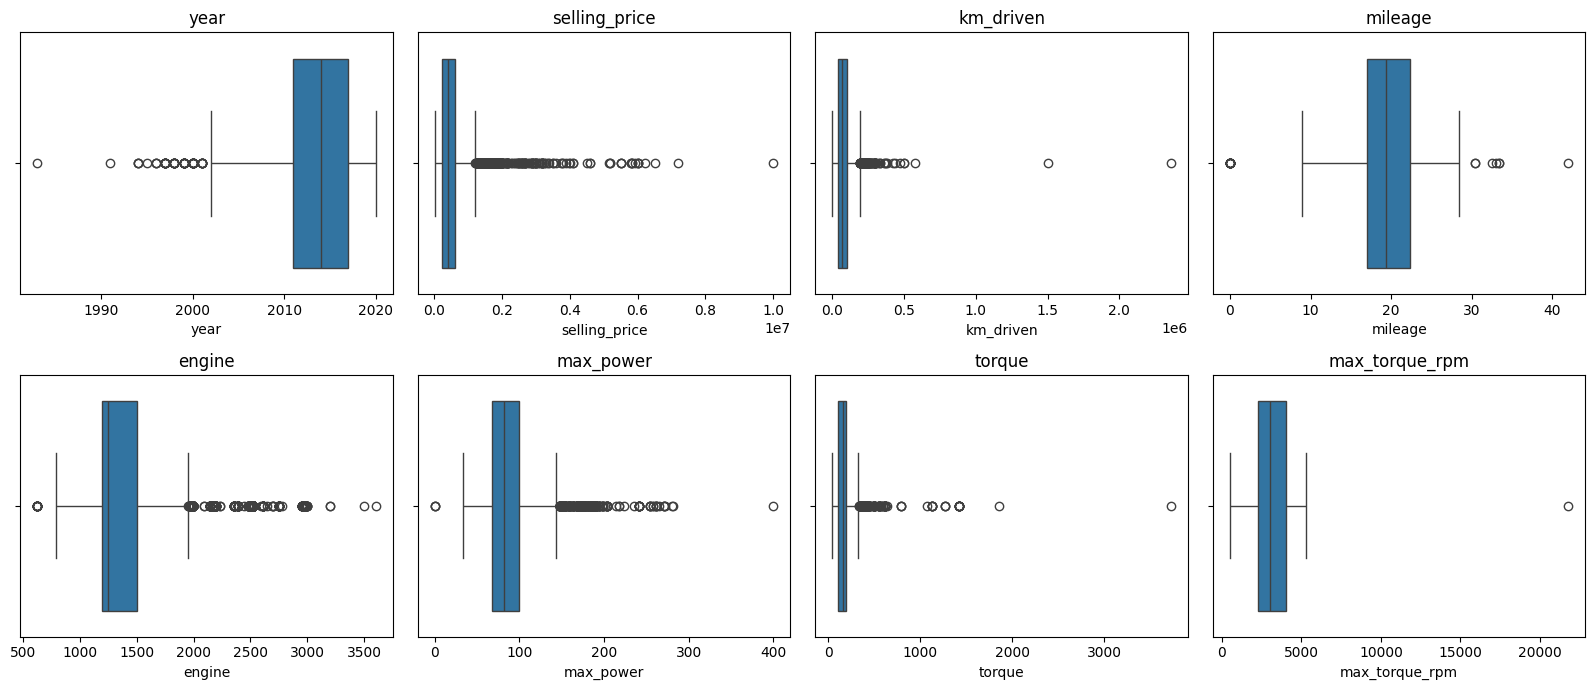

In [71]:
numeric = df_train.select_dtypes(include="number").drop(columns="seats")

fig, axes = plt.subplots(2, 4, figsize=(16, 7))

for col, ax in zip(numeric.columns, axes.flat):
    sns.boxplot(x=numeric[col], ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()

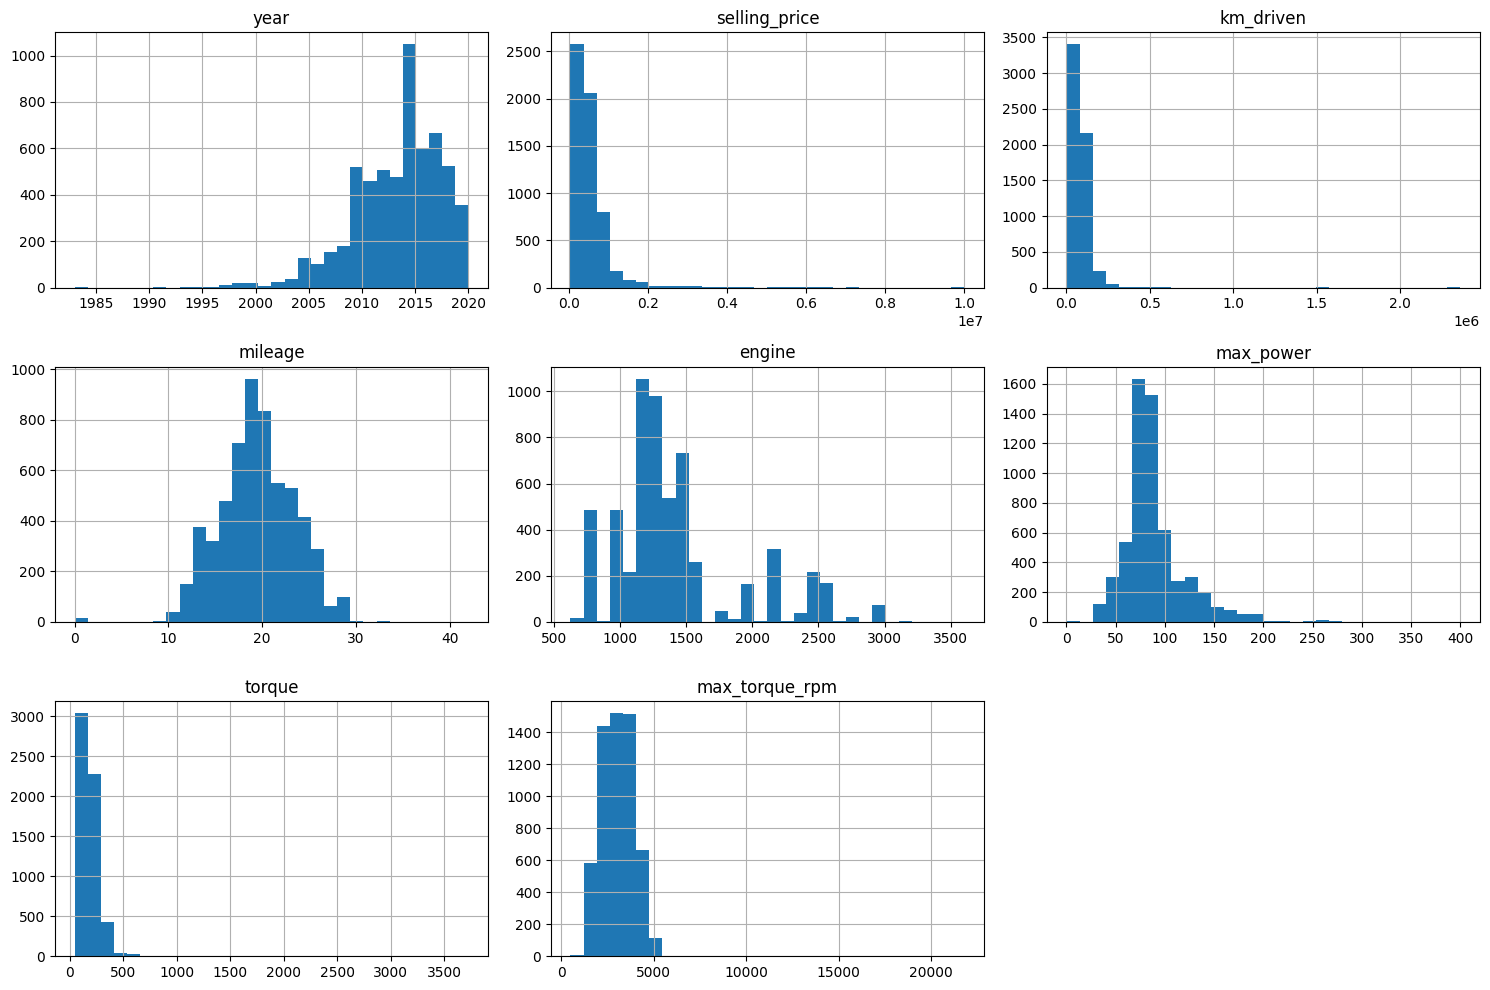

In [72]:
numeric.hist(bins=30, figsize=(15, 10))
plt.tight_layout()
plt.show()

In [73]:
limit = df_train["km_driven"].quantile(0.99)

for df in [X_train_feature_engineering, X_test_feature_engineering]:
    df["km_driven"] = df["km_driven"].clip(upper=limit)

In [74]:
for df in [X_train_feature_engineering, X_test_feature_engineering]:
    df["log_km_driven"] = np.log1p(df["km_driven"])

In [75]:
for df in [X_train_feature_engineering, X_test_feature_engineering]:
    df["log_max_power"] = np.log1p(df["max_power"])

In [76]:
ridge_search = GridSearchCV(
    make_pipeline(encoder, StandardScaler(), Ridge()),
    param_grid={"ridge__alpha": alphas},
    cv=10,
    scoring="r2"
)

ridge_search.fit(X_train_feature_engineering, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 6] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [6] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [6] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [6] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown ca

GridSearchCV(cv=10,
             estimator=Pipeline(steps=[('columntransformer',
                                        ColumnTransformer(remainder='passthrough',
                                                          transformers=[('ohe',
                                                                         OneHotEncoder(drop='first',
                                                                                       handle_unknown='ignore',
                                                                                       sparse_output=False),
                                                                         ['name',
                                                                          'fuel',
                                                                          'seller_type',
                                                                          'transmission',
                                                                          'owner',
                                                                          'seats',
                                                                          'model_name'])])),
                                       ('standardscaler', StandardScaler()),
                                       ('ridge', Ridge())]),
             param_grid={'ridge__alpha': array([1.e-02, 1.e-01, 1.e+00, 1.e+01, 1.e+02, 1.e+03, 1.e+04, 1.e+05,
       1.e+06])},
             scoring='r2')

In [77]:
ridge_search.best_params_

{'ridge__alpha': np.float64(1000.0)}

In [78]:
pred_train = ridge_search.predict(X_train_feature_engineering)
pred_test = ridge_search.predict(X_test_feature_engineering)

r2_score(y_train, pred_train), r2_score(y_test, pred_test), MSE(y_train, pred_train), MSE(y_test, pred_test)

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 6] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


(0.9009292874147259, 0.9108062472438386, 28397464435.374725, 51271116068.79674)

Как видим качество улучшилось существенно: R2 вырос с 0.77 до 0.91, MSE упал с 129 млрд. до 51.3 млрд.

# **Часть 5 | Бизнесовая (0.4 балла)**

### **Задание 25 (0.2 балла)**

В мире бизнеса очень важно давать оценку качества модели понятную бизнесу, поэтому иногда заказчики приходят с кастомными метриками. Попробуем сделать такую для нашей задачи.

**Описание метрики:**

Среди всех предсказанных цен на авто нужно посчитать долю прогнозов, отличающихся от реальных цен на эти авто не более чем на 10% (в одну или другую сторону). Отклонение считается относительно **реальной** цены $y_i$:

$$\text{business\_metrics}(y, \hat y) = \frac{1}{n}\sum_{i=1}^{n} \mathbb{1}\left[\frac{|\hat y_i - y_i|}{y_i} \le 0.1\right]$$

**Ваша задача:**

- [ ] Реализуйте метрику `business_metrics`
- [ ] Посчитайте метрику для всех обученных моделей и определите, какая лучше всего решает задачу бизнеса

In [79]:
def business_metrics(y_true, y_pred):
  y_true = np.asarray(y_true)
  y_pred = np.asarray(y_pred)
  return np.mean(np.abs(y_true - y_pred) / y_true <= 0.1)

In [80]:
ridge_base = make_pipeline(StandardScaler(), Ridge(alpha=1000))
ridge_base.fit(X_train_encoded, y_train)

pred_train_base = ridge_base.predict(X_train_encoded)
pred_test_base = ridge_base.predict(X_test_encoded)

In [81]:
weights_l0 = min(
  candidates,
  key=lambda item: item[0] + 1e8 * np.count_nonzero(item[1][1:])
)[1]

scores = {
  "LinearRegression": business_metrics(y_test, model.predict(X_test_scaled)),
  "Lasso": business_metrics(y_test, lasso.predict(X_test_scaled)),
  "Lasso CV": business_metrics(y_test, lasso_search.predict(X_test)),
  "ElasticNet CV": business_metrics(y_test, elastic_search.predict(X_test)),
  "L0": business_metrics(y_test, test @ weights_l0),
  "Ridge": business_metrics(y_test, pred_test_base),
  "Ridge Feature Engineering": business_metrics(y_test, ridge_search.predict(X_test_feature_engineering))
}

scores

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 6] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


{'LinearRegression': np.float64(0.242),
 'Lasso': np.float64(0.242),
 'Lasso CV': np.float64(0.24),
 'ElasticNet CV': np.float64(0.24),
 'L0': np.float64(0.242),
 'Ridge': np.float64(0.311),
 'Ridge Feature Engineering': np.float64(0.356)}

Лучше всех справилась Ridge после Feature Engineering, 35,7% предсказаний ошибаются не более чем на 10%

### **Задание 26 (0.2 балла)**

Но у бизнеса не всегда есть идеи и иногда задача на выбор метрики делегируется вам.

**Задание:**

- [ ] Придумайте и реализуйте другую кастомную метрику с учетом того, что модель не должна сильно ошибаться в прогнозе, но недопрогноз для модели, согласно мнению бизнеса, хуже, чем перепрогноз.
- [ ] Посчитайте метрику для всех обученных моделей и определите, какая лучше всего решает задачу бизнеса

In [82]:
def your_business_metrics(y_true, y_pred, under_limit=50_000, over_limit=100_000):
  y_true = np.asarray(y_true)
  y_pred = np.asarray(y_pred)

  return np.mean(
      (y_pred >= y_true - under_limit) &
      (y_pred <= y_true + over_limit)
  )

In [83]:
weights_l0 = min(
  candidates,
  key=lambda item: item[0] + 1e8 * np.count_nonzero(item[1][1:])
)[1]

scores = {
  "LinearRegression": your_business_metrics(y_test, model.predict(X_test_scaled)),
  "Lasso": your_business_metrics(y_test, lasso.predict(X_test_scaled)),
  "Lasso CV": your_business_metrics(y_test, lasso_search.predict(X_test)),
  "ElasticNet CV": your_business_metrics(y_test, elastic_search.predict(X_test)),
  "L0": your_business_metrics(y_test, test @ weights_l0),
  "Ridge": your_business_metrics(y_test, pred_test_base),
  "Ridge Feature Engineering": your_business_metrics(y_test, ridge_search.predict(X_test_feature_engineering))
}

scores

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 6] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


{'LinearRegression': np.float64(0.37),
 'Lasso': np.float64(0.37),
 'Lasso CV': np.float64(0.372),
 'ElasticNet CV': np.float64(0.372),
 'L0': np.float64(0.366),
 'Ridge': np.float64(0.456),
 'Ridge Feature Engineering': np.float64(0.54)}

Лучше всех справилась Ridge после Feature Engineering, 54% предсказаний уложились в заданные денежные допуски, при этом недооценку оценивали строже, чем переоценку.

# **Часть 6 | Оформление репозитория (2 балла)**

Домашнее задание оформите как репозиторий на GitHub.

---

### Обязательные файлы:

1. **`.ipynb`-ноутбук** со всеми экспериментами (0.5 балла):

   * полный EDA,
   * все шаги препроцессинга,
   * обучение и сравнение моделей,
   * сохранённые output’ы;
   * ноутбук запускается сверху вниз без ошибок.

2. **`.pickle`-файл** (0.5 балла), содержащий:

   * обученную модель (или пайплайн `scaler + model`);
   * параметры скейлинга;
   * любые числовые объекты, необходимые для инференса внутри Streamlit-приложения.

   Файл должен загружаться и делать предсказание на новых объектах.

3. **`.md`-файл с выводами** о проделанной работе (1 балл):

   * что было сделано (краткое описание каждого этапа), какие результаты были получены (метрики + интерпретация), что дало наибольший прирост качества (0.75 балла);
   * что сделать не удалось и почему — это нормально и даже полезно (0.25 балла).


### **За что могут быть сняты баллы:**

* отсутствие `.pickle` с моделью / пайплайном;
* слабая или неполная аналитика в `.md`-файле;
* беспорядок в ноутбуке или неясная логика вычислений.

In [84]:
def prepare_features(data, medians, limit, pattern, columns):
  df = data.drop(columns="selling_price", errors="ignore").copy()

  for col, unit in [
      ("mileage", r"kmpl|km/kg"),
      ("engine", "CC"),
      ("max_power", "bhp"),
  ]:
      df[col] = pd.to_numeric(
          df[col].astype("string").str.replace(unit, "", regex=True).str.strip(),
          errors="coerce"
      )

  torque = df["torque"].astype("string").str.lower().str.replace(",", "", regex=False)
  numbers = torque.str.findall(r"\d+(?:\.\d+)?")

  df["torque"] = pd.to_numeric(numbers.str[0], errors="coerce")
  df.loc[torque.str.contains("kg", na=False), "torque"] *= 9.8
  df["max_torque_rpm"] = pd.to_numeric(
      numbers.str[1:].str[-1], errors="coerce"
  )

  for col in ["year", "km_driven", "seats"]:
      df[col] = pd.to_numeric(df[col], errors="coerce")

  df = df.fillna(medians)
  df[["engine", "seats"]] = df[["engine", "seats"]].astype(int)

  df["model_name"] = df["name"].str.lower().str.extract(pattern, expand=False)
  df["name"] = df["name"].str.split().str[0]

  df["max_power_squared"] = df["max_power"] ** 2
  df["mileage_squared"] = df["mileage"] ** 2
  df["power_per_liter"] = df["max_power"] / (df["engine"] / 1000)
  df["torque_rpm"] = df["torque"] * df["max_torque_rpm"]

  df["km_driven"] = df["km_driven"].clip(upper=limit)
  df["log_km_driven"] = np.log1p(df["km_driven"])
  df["log_max_power"] = np.log1p(df["max_power"])

  return df[columns]

In [86]:
!pip install cloudpickle # чтобы не переопределять функцию, а запечь в бинарнике

In [87]:
from sklearn.preprocessing import FunctionTransformer
from sklearn.pipeline import Pipeline
import cloudpickle

pipeline = Pipeline([
  ("features", FunctionTransformer(
    prepare_features,
    kw_args={
      "medians": medians.drop("selling_price", errors="ignore"),
      "limit": limit,
      "pattern": pattern,
      "columns": X_train_feature_engineering.columns.tolist(),
    }
  )),
  ("model", ridge_search.best_estimator_),
])

with open("model.pickle", "wb") as f:
    cloudpickle.dump(pipeline, f)

In [88]:
with open("model.pickle", "rb") as f:
    loaded_model = cloudpickle.load(f)

raw_test = pd.read_csv(
    "https://raw.githubusercontent.com/Murcha1990/MLDS_ML_2022/main/Hometasks/HT1/cars_test.csv"
)

predictions = loaded_model.predict(raw_test)

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 6] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


In [89]:
np.testing.assert_allclose(
    predictions,
    ridge_search.predict(X_test_feature_engineering)
)

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 6] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


# **<font color="green">Часть 7 | Создание интерактивного приложения на Streamlit (3 балла)</font>**

Вам необходимо создать интерактивное приложение на Streamlit (например, `app.py`), которое запускается командой

```bash
streamlit run app.py
```

и опубликовать его в [Streamlit Community Cloud](https://streamlit.io/cloud). Приложение должно:

- показывать основные информативные графики/гистограммы в рамках EDA (0.75 балла);
- на вход запрашивать csv-файл с признаками объектов или запрашивать признаки объекта в окошках для ввода, и применять на поступивших объектах модель из `.pickle`-файла (1 балл);
- визуализировать веса (коэффициенты) обученной модели (0.75 балла).

**Оценка сервиса (0.5 балла).** Дополните `.md`-файл из Части 6 разделом об оценке приложения:

* насколько приложение удобно в использовании;
* что получилось визуализировать хорошо, а что — менее удачно;
* какие ограничения или проблемы вы заметили;
* какие улучшения планируете в следующей итерации.

**Что нужно сдать:** код приложения в репозитории из Части 6 и ссылку на приложение в Streamlit Community Cloud.

**За что могут быть сняты баллы:** приложение не запускается командой выше или ссылка на него не открывается.